In [1]:
# BƯỚC 1: KHAI BÁO THƯ VIỆN VÀ TẢI DỮ LIỆU
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score
from scipy.stats import mode

# Tải bộ dữ liệu Breast Cancer Wisconsin (Diagnostic)
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target  # 0: Ác tính (malignant), 1: Lành tính (benign)

print(f"Số lượng mẫu dữ liệu: {X.shape[0]}")
print(f"Số lượng thuộc tính tế bào: {X.shape[1]}")
print(f"Các lớp phân loại thực tế: {cancer.target_names} (0: Ác tính, 1: Lành tính)")
print("Số mẫu thực tế mỗi lớp:", dict(zip(cancer.target_names, np.bincount(y))))

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Số lượng mẫu dữ liệu: 569
Số lượng thuộc tính tế bào: 30
Các lớp phân loại thực tế: ['malignant' 'benign'] (0: Ác tính, 1: Lành tính)
Số mẫu thực tế mỗi lớp: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


In [2]:
# BƯỚC 2: CHUẨN HÓA DỮ LIỆU VÀ GOM CỤM BẰNG K-MEANS
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Chuẩn hóa dữ liệu bằng StandardScaler để các thuộc tính có cùng thang đo
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Gom cụm K-Means với k = 2 (tương ứng 2 nhóm u: lành tính và ác tính)
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print("Đã hoàn tất quá trình gom cụm dữ liệu khối u bằng K-Means.")
unique, counts = np.unique(clusters, return_counts=True)
for u, c in zip(unique, counts):
    print(f" - Cụm {u}: {c} mẫu")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Đã hoàn tất quá trình gom cụm dữ liệu khối u bằng K-Means.
 - Cụm 0: 375 mẫu
 - Cụm 1: 194 mẫu


In [3]:
# BƯỚC 3: ÁNH XẠ CỤM VÀ ĐÁNH GIÁ ĐỘ CHÍNH XÁC GOM CỤM
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Gán nhãn cho từng cụm dựa theo nhãn thực tế chiếm đa số trong cụm
labels_mapped = np.zeros_like(clusters)
for i in range(2):
    mask = (clusters == i)
    if np.sum(mask) > 0:
        majority_class = mode(y[mask], keepdims=True)[0][0]
        labels_mapped[mask] = majority_class
        print(f"Cụm {i} được ánh xạ về nhóm: Lớp {majority_class} ({cancer.target_names[majority_class]})")

# Tính toán các chỉ số đánh giá
acc = accuracy_score(y, labels_mapped)
sil = silhouette_score(X_scaled, clusters)

print(f"\n=> Độ chính xác (Accuracy) của K-Means so với thực tế: {acc * 100:.2f}%")
print(f"=> Hệ số Dáng điệu (Silhouette Coefficient): {sil:.4f}\n")

print("--- BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE) ---")
print(classification_report(y, labels_mapped, target_names=cancer.target_names, digits=4))

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Cụm 0 được ánh xạ về nhóm: Lớp 1 (benign)
Cụm 1 được ánh xạ về nhóm: Lớp 0 (malignant)

=> Độ chính xác (Accuracy) của K-Means so với thực tế: 90.51%
=> Hệ số Dáng điệu (Silhouette Coefficient): 0.3434

--- BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE) ---
              precision    recall  f1-score   support

   malignant     0.9072    0.8302    0.8670       212
      benign     0.9040    0.9496    0.9262       357

    accuracy                         0.9051       569
   macro avg     0.9056    0.8899    0.8966       569
weighted avg     0.9052    0.9051    0.9042       569



Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


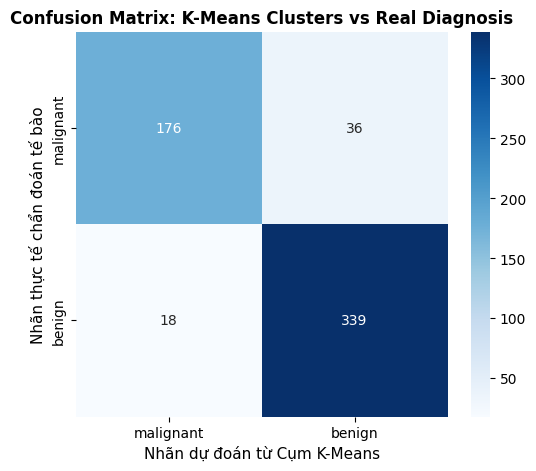

Nhận xét: K-Means phân tách chính xác trên 90% số lượng ca bệnh mà không cần nhãn giám sát ban đầu.


In [4]:
# BƯỚC 4: MA TRẬN NHẦM LẪN SO SÁNH GOM CỤM VÀ NHÃN THỰC TẾ
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

cm = confusion_matrix(y, labels_mapped)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names,
            yticklabels=cancer.target_names)

plt.title("Confusion Matrix: K-Means Clusters vs Real Diagnosis", fontsize=12, fontweight='bold')
plt.xlabel("Nhãn dự đoán từ Cụm K-Means", fontsize=11)
plt.ylabel("Nhãn thực tế chẩn đoán tế bào", fontsize=11)
plt.show()

print("Nhận xét: K-Means phân tách chính xác trên 90% số lượng ca bệnh mà không cần nhãn giám sát ban đầu.")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


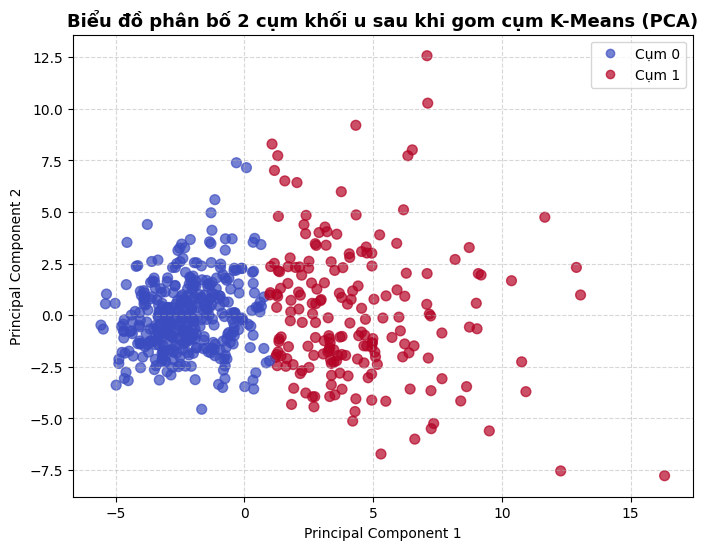

In [5]:
# BƯỚC 5: TRỰC QUAN HÓA KẾT QUẢ GOM CỤM BẰNG BIỂU ĐỒ 2D (PCA)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='coolwarm', alpha=0.7, s=50)
plt.title("Biểu đồ phân bố 2 cụm khối u sau khi gom cụm K-Means (PCA)", fontsize=13, fontweight='bold')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(handles=scatter.legend_elements()[0], labels=['Cụm 0', 'Cụm 1'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()